In [1]:
# importing important libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
# Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Target Classes:", iris.target_names)

Dataset Shape: (150, 4)
Target Classes: ['setosa' 'versicolor' 'virginica']


In [3]:
# Splitting dataset into train and test (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (120, 4)
Testing Data Shape: (30, 4)


In [5]:
# Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# Initialize models
knn_model = KNeighborsClassifier(n_neighbors=3)

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

In [7]:
# Train KNN
knn_model.fit(X_train, y_train)

# Train SVM
svm_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [8]:
# Make predictions
knn_pred = knn_model.predict(X_test)
svm_pred = svm_model.predict(X_test)

In [9]:
# Calculating Accuracy
knn_accuracy = accuracy_score(y_test, knn_pred)
svm_accuracy = accuracy_score(y_test, svm_pred)

print("KNN Accuracy:", knn_accuracy * 100, "%")
print("SVM Accuracy:", svm_accuracy * 100, "%")

KNN Accuracy: 93.33333333333333 %
SVM Accuracy: 96.66666666666667 %


In [15]:
# Create Comparison DataFrame
comparison = pd.DataFrame({
    'Algorithm': ['KNN', 'SVM'],
    'Configuration': ['K = 3', 'RBF Kernel'],
    'Accuracy': [
        knn_accuracy * 100,
        svm_accuracy * 100
    ]
})

print(comparison)

  Algorithm Configuration   Accuracy
0       KNN         K = 3  93.333333
1       SVM    RBF Kernel  96.666667


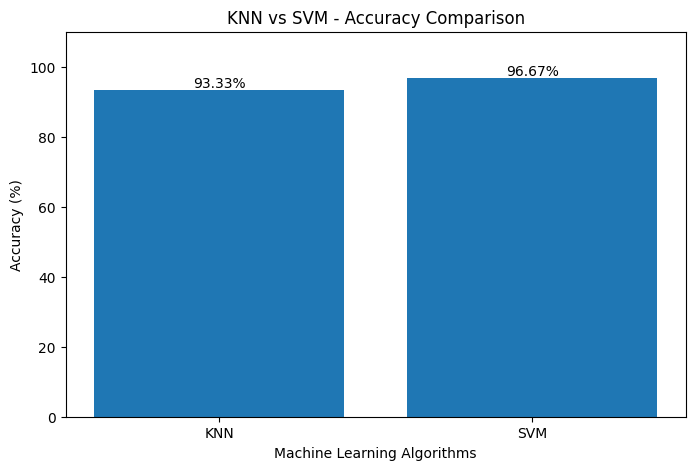

In [11]:
# Visualize Model Comparison
plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison['Algorithm'],
    comparison['Accuracy']
)

plt.title("KNN vs SVM - Accuracy Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 110)

plt.bar_label(bars, fmt='%.2f%%')

plt.show()

In [12]:
# Compare Classification Reports
print("========== KNN CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    knn_pred,
    target_names=iris.target_names
))

print("========== SVM CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    svm_pred,
    target_names=iris.target_names
))

========== KNN CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

========== SVM CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



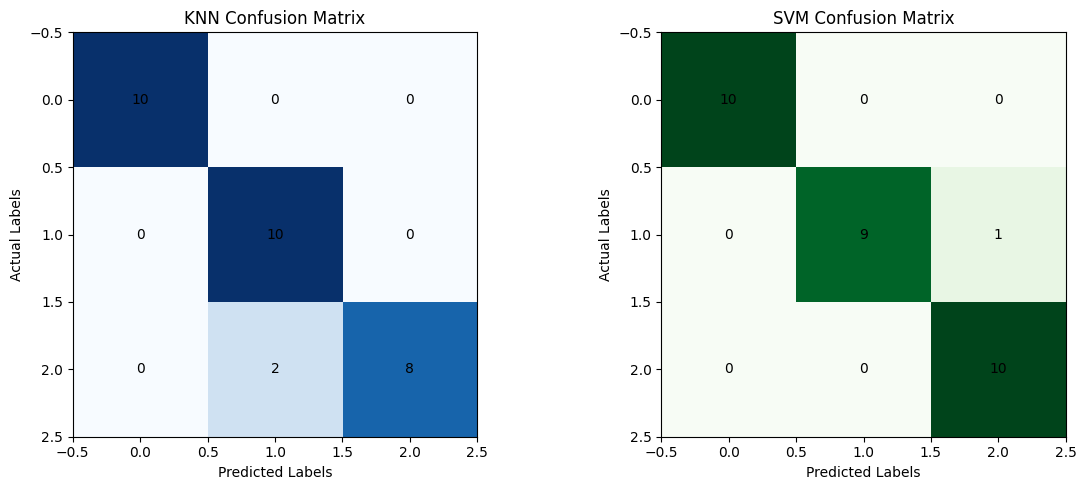

In [13]:
# Confusion Matrix Comparison

knn_cm = confusion_matrix(y_test, knn_pred)
svm_cm = confusion_matrix(y_test, svm_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# KNN Confusion Matrix
axes[0].imshow(knn_cm, cmap='Blues')

axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted Labels")
axes[0].set_ylabel("Actual Labels")

# Add values inside cells
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, knn_cm[i, j],
                     ha='center', va='center')

# SVM Confusion Matrix
axes[1].imshow(svm_cm, cmap='Greens')

axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted Labels")
axes[1].set_ylabel("Actual Labels")

for i in range(3):
    for j in range(3):
        axes[1].text(j, i, svm_cm[i, j],
                     ha='center', va='center')

plt.tight_layout()
plt.show()

In [16]:
# Identify the best model
if knn_accuracy > svm_accuracy:
    print("KNN performed better in this experiment!")

elif svm_accuracy > knn_accuracy:
    print("SVM performed better in this experiment!")

else:
    print("Both models achieved the same accuracy!")

SVM performed better in this experiment!


In [17]:
# Final observation
print("========== FINAL MODEL COMPARISON ==========")

print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")
print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

print("\nConclusion:")

if knn_accuracy > svm_accuracy:
    print("KNN achieved higher accuracy on the test dataset.")

elif svm_accuracy > knn_accuracy:
    print("SVM achieved higher accuracy on the test dataset.")

else:
    print("Both algorithms achieved equal accuracy.")

print("\nBoth models were trained and evaluated using the same dataset and test split.")

========== FINAL MODEL COMPARISON ==========
KNN Accuracy: 93.33%
SVM Accuracy: 96.67%

Conclusion:
SVM achieved higher accuracy on the test dataset.

Both models were trained and evaluated using the same dataset and test split.
